# Assignment 4

In [70]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import time
import ipywidgets as widgets
from IPython.display import display

In [71]:
BOOK_PATH = "goblet_book.txt"

## Data Handler Class

In [ ]:
class DataHandler:
    """
    Class for data management.

    Args:
        file_name: The name of the file to read.
    Attributes:
        data: The data read from the file.
        data_vector: A list of unique characters in the data.
        K: Dim. of the data (length of data_vector).
    """

    def __init__(self, file_name):

        # Load data:
        try:
            with open(file_name, "r", encoding="utf-8") as fid:
                self.data = fid.read()
        except FileNotFoundError:
            raise FileNotFoundError(f"Could not find file: {file_name}")
        
        # Store characters, length and dimension
        self.data_vector = list(set(self.data))
        self.K = len(self.data_vector)
        self.N = len(self.data)

        # Create fast lookup dictionaries
        self.char_to_ind_dict = {char: ind for ind, char in enumerate(self.data_vector)}
        self.ind_to_char_dict = {ind: char for ind, char in enumerate(self.data_vector)}

        # Prepare a rng (which will likely be updated by network later)
        self.rng = np.random.default_rng()
        
        # Print status
        print(f"DataHandler: Loaded file {file_name} with dimension {self.K} of length {self.N}.")

    def char_to_ind(self, char):
        """
        Convert a character to an index based on the dict. char_to_ind_dict.

        Args:
            char: The character to convert.
        Returns:
            The index of the character in the data vector.
        """
        return self.char_to_ind_dict[char]
    
    def sec_to_one_hot(self, sec):
        seq_len = len(sec)
        one_hot = np.zeros((self.K, seq_len))
        indices = [self.char_to_ind_dict[c] for c in sec]
        one_hot[indices, np.arange(seq_len)] = 1
        return one_hot

    def ind_to_char(self, ind):
        """
        Convert an index to a character based on the dict. ind_to_char_dict.

        Args:
            ind: The index to convert.
        Returns:
            The character corresponding to the index in the data vector.
        """
        return self.ind_to_char_dict[ind]
    
    def get_input_seq(self, e, seq_length):
        return self.data[e:e+seq_length]
    
    def get_target_seq(self, e, seq_length):
        return self.data[e+1 : e+seq_length+1]
    
    def get_target_indices(self, e, seq_length):
        raw_str = self.get_target_seq(e, seq_length)
        return np.array([self.char_to_ind_dict[c] for c in raw_str])
    
    # Note that the following two functions should be possible
    # to combine and make shorter...
    def get_input_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_input_seq(e, seq_length))
    
    def get_target_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_target_seq(e, seq_length))

    def get_random_char_one_hot(self):
        random_char = self.rng.choice(self.data_vector)
        return self.sec_to_one_hot(random_char)

We explore the data a bit before continuing...

In [73]:
data_handler = DataHandler(BOOK_PATH)
# print(f"data_vector: {data_handler.data_vector}")
# print(f"char_to_ind_dict: {data_handler.char_to_ind_dict}")
# print(f"ind_to_char_dict: {data_handler.ind_to_char_dict}")

DataHandler: Loaded file goblet_book.txt with dimension 80 of length 1107542.


## Neural Network Class

In [74]:
class Activation:
    @staticmethod
    def softmax(X, T=1.0):
        """
        Softmax activation function, optionally with temperature scaling.

        Args:
            X (np.ndarray): Input array of shape (K, N)
            T (float, optional): Temperature [0, 1].
        Returns:
            np.ndarray: Output array of shape (K, N)
        """
        if T is not None:
            if T < 0 or T > 1.0:
                raise ValueError("Softmax temperature must be in the range [0, 1].")
            if T == 0:
                # Potentially add protection against 0 division
                pass
        # Catch None case
        if T is None:
            T = 1.0
        # Apply temperature scaling (note that T=1.0 is same as no temperature)
        shifted_X = (X - np.max(X, axis=0, keepdims=True)) / T
        exp_Z = np.exp(shifted_X)
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(**kwargs):
        """
        Args:
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        X = kwargs['X']
        Y = kwargs['Y']
        P = Activation.softmax(X=X)
        return P - Y  # Return P - Y_labels directly
    
    @staticmethod
    def tahn(X):
        """
        Tanh activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.tanh(X)
    @staticmethod
    def tahn_derivative(**kwargs):
        """
        Tanh derivative function.

        Source: https://medium.com/@vikrampande783/derivative-of-sigmoid-and-tanh-ffdea6efb464

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * (1 - Y**2)

In [75]:
class Layer:

    def __init__(self, net, lam, activation):
        self.prev_layer = None
        self.next_layer = None

        self.net = net
        self.lam = lam

        self.X = []
        self.Y = []
        self.Z = []

        self.G = None # Holds gradients to be passed to upper layer

        if activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        elif activation == "tanh":
            self.activation_func = Activation.tahn
            self.activation_func_derivative = Activation.tahn_derivative
        else:
            raise(f"Unsupported activation detected.")

    def update_params(self, eta):
        pass

    def clear(self):
        pass

    def get_X(self):
        return self.X[-1] if isinstance(self.X, list) else self.X
    def get_first_X(self):
        return self.X[0] if isinstance(self.X, list) else self.X
    
    def get_Y(self):
        return self.Y[-1] if isinstance(self.Y, list) else self.Y
    def get_first_Y(self):
        return self.Y[0] if isinstance(self.Y, list) else self.Y
    
    def get_Z(self):
        if len(self.Z) == 0:
            return None
        return self.Z[-1] if isinstance(self.Z, list) else self.Z

In [76]:
class FullyConnectedLayer(Layer):
    def __init__(self, net, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        W: (neurons in net., input. dim.) = (m, d)
        b: (neurons in net., 1) = (m, 1)

        Args:
            net: The neural network to which this layer belongs
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(m))*self.net.rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))

        self.grad_W = \
        self.grad_b = None

    def clear(self, **kwargs):
        self.X = []
        self.Y = []
        self.Z = []

    def forward(self, X = None, save_state=True, T=None, theta=None):
        """
        Forward pass.   

        Args:
            X: Input data of shape (d, N)
            save_state (boolean): Determined if it should save state to layer
            T (float): Temperature in range [0, 1]
        """
        if X is None and save_state and self.prev_layer is not None:
            X = self.prev_layer.get_Z()

        # Store X, Y, Z or return Z
        Y = self.W @ X + self.b
        Z = self.activation_func(X=Y, T=T)

        if theta is not None:
            """
            Note that this section was first written using a loop but was
            changed drastically after code review performed by Gemini.
            """
            # 1. Sort in descending order (note - sign)
            Z_idx_desc = np.argsort(-Z, axis=0)
            # 2. Reorder Z using decending indicies
            Z_sorted = np.take_along_axis(Z, Z_idx_desc, axis=0)
            # 3. Calculate cumulative sum down the columns
            cum_sum = np.cumsum(Z_sorted, axis=0)
            # 4. Create a mask for removing elements
            # The goal is remove all elements efter the crossing of the
            # threshold and shifting it down by one to keep the element 
            # crossing it
            mask = cum_sum >= theta
            mask = np.roll(mask, shift=1, axis=0)
            mask[0, :] = False # Prevent removal of top probaiblity even if it's > theta
            # 5. Apply the mask
            Z_sorted[mask] = 0.
            # 6. Restore the propabilities into original order
            Z = np.zeros_like(Z)
            np.put_along_axis(Z, Z_idx_desc, Z_sorted, axis=0)
            # 7. Renormalize
            Z = Z / np.sum(Z, axis=0, keepdims=True)

        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        return Z
    
    def backward(self, Y):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)
        
        # And a list of grads (dL/dht) for each timestep to pass
        G = [None] * T # List to store dL/dht for each timestep

        # Go trough time
        for t in range(T):

            # Get predicted pt and yt
            y_t = Y[:, :, t]
            
            # Calc. gradient
            g_t = self.activation_func_derivative(X = self.Y[t], Y = y_t)
            
            # Adjust weight and bias gradients
            self.grad_W += g_t @ self.X[t].T
            self.grad_b += np.sum(g_t, axis=1, keepdims=True)
            
            # Compute dL/dh_t to pass back to next layer
            G[t] = self.W.T @ g_t

        # Average gradients over time steps * batch size and store grads.
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

    def update_params_adam(self, eta, t):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [77]:
class RecurrentLayer(Layer):
    def __init__(self, net, K, m, activation, lam = 0.):
        """
        Initializes the recurrent layer.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (m, m))
        self.U = (1/np.sqrt(2*K))*self.net.rng.standard_normal(size = (m, K))
        self.b = np.zeros((m, 1))

        self.grad_W = np.zeros((m, m))
        self.grad_U = np.zeros((m, K))
        self.grad_b = np.zeros((m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        
        # Reset Z to only contain the last state
        if h_last is not None and force == False:
            self.Z = [h_last]
        else:
            self.Z = []

    def forward(self, X = None, h_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # h_prev shape = (m, N) = Hidden neurons, num. of data entries
        if h_prev is None:
            h_prev = self.get_Z()
            if h_prev is None:
                h_prev = np.zeros((self.W.shape[0], X.shape[1]))
                if save_state:
                    self.Z.append(h_prev)

        # Calc. and store X, Y, Z
        # print(f"self.W.shape: {self.W.shape}")
        # print(f"h_prev.shape: {h_prev.shape}")
        # print(f"self.U.shape: {self.U.shape}")
        # print(f"self.b.shape: {self.b.shape}")
        Y = self.W @ h_prev + self.U @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        else:
            return Z

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_U = np.zeros_like(self.U)
        self.grad_b = np.zeros_like(self.b)
        
        # Prepare new grad. matrix and get prev.
        G_next = np.zeros((self.W.shape[0], 1))
        G_prev = self.next_layer.G

        for t in reversed(range(T)):
            # Sum gradient from prev. layer and total
            G_t = G_prev[t] + G_next
            
            # Get. activation der.
            G_y = self.activation_func_derivative(G = G_t, Y = self.Z[t+1])
            
            # Accumulate weight gradients
            # Previous hidden state h_{t-1} is self.Z[t-1] or zero if t=0
            #z_prev = self.Z[t] if t > 0 else np.zeros_like(self.Z[0])
            z_prev = self.Z[t]
            
            # Compute new grads.
            self.grad_W += G_y @ z_prev.T
            self.grad_U += G_y @ self.X[t].T
            self.grad_b += np.sum(G_y, axis=1, keepdims=True)
            
            # Compute gradient for the previous timestep (t-1)
            G_next = self.W.T @ G_y

        # Average gradients over time steps * batch size and store
        self.grad_W /= (T * self.X[0].shape[1])
        self.grad_U /= (T * self.X[0].shape[1])
        self.grad_b /= (T * self.X[0].shape[1])
        self.G = G_next
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.U_m = np.zeros_like(self.U)
            self.U_v = np.zeros_like(self.U)

            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.U_m = beta1 * self.U_m + (1 - beta1) * self.grad_U
        self.U_v = beta2 * self.U_v + (1 - beta2) * (self.grad_U**2)
        # Compute the bias corrected estimate
        u_m_hat = self.U_m / (1 - beta1**t)
        u_v_hat = self.U_v / (1 - beta2**t)
        # Update params
        self.U -= eta * u_m_hat / (np.sqrt(u_v_hat) + 1e-8)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [78]:
class RecurrentNeuralNetwork:
    """
    Recurrent Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self, data_handler):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """
        self.layers = []
        self.input_layer =  self.output_layer = None

        self.h = None

        self.avg_loss = 0.

        self.training_loss_history = \
            self.validation_loss_history = \
            self.training_cost_history = \
            self.validation_cost_history = \
            self.training_acc_history = \
            self.validation_acc_history = None

        # We allways keep a new random number generator in the class for reproducibility
        self.rng = np.random.default_rng()
        # get the BitGenerator used by default_rng
        BitGen = type(self.rng.bit_generator)
        # use the state from a fresh bit generator
        seed = 42
        self.rng.bit_generator.state = BitGen(seed).state

        self.data_handler = data_handler
        self.data_handler.rng = self.rng

        self.smooth_loss_history = []

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                grads['V'] = layer.grad_W
                grads['c'] = layer.grad_b
            if layer.__class__.__name__ == "RecurrentLayer":
                grads['W'] = layer.grad_W
                grads['U'] = layer.grad_U
                grads['b'] = layer.grad_b
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['V'] = layer.W
                net['c'] = layer.b
            if layer.__class__.__name__ == "RecurrentLayer":
                net['W'] = layer.W
                net['U'] = layer.U
                net['b'] = layer.b
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            # Make connections before appending to the layers list
            l.prev_layer = self.layers[-1] if self.layers else None
            if len(self.layers) > 0:
                self.layers[-1].next_layer = l
            else:
                self.input_layer = l
            self.output_layer = l
            # Append to layer list
            self.layers.append(l)

    def reset_layers(self):
        """
        Reset all layers.

        Empties X, Y and Z of each layer.
        """
        for l in self.layers:
            l.X = l.Y = l.Z = []
        
    def synthesize(self, n, h_init = None, X = None, T=None, theta=None):
        """
        Synthesize a sequence of characters.

        Args:
            n (int):
            h_init:
            X:
            T (float): Temperature in range [0, 1] (optional)

        Returns:
             Y: List of generated character of length n
        """

        #self.clear_layers()
        h_prev = h_init if h_init is not None else np.zeros((self.layers[0].W.shape[0], 1))

        Y = []
        if X is None:
            X = self.data_handler.get_random_char_one_hot()
        #print(f"X.shape: {X.shape}")

        for _ in range(n):
            current_input = X
            for layer in self.layers:
                if isinstance(layer, RecurrentLayer):
                    current_input = layer.forward(X=current_input, h_prev=h_prev, save_state=False)
                    h_prev = current_input 
                elif isinstance(layer, FullyConnectedLayer):
                    current_input = layer.forward(X=current_input, save_state=False, T=T, theta=theta)
            P = current_input
            cp = np.cumsum(P, axis=0)
            a = self.rng.uniform(size=1)
            ii = np.argmax(cp - a > 0)

            Y.append(self.data_handler.ind_to_char(ii))

            x = np.zeros_like(X)
            x[ii, 0] = 1
            X=x

        return Y

    def compute_loss(self, P, Y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (K, N) containing the correct one-hot-encoded labels for each sample

        Returns:
            loss: The computed loss value
        """
        P = np.asarray(P)
        Y = np.asarray(Y)
        # Divide by (batch_size * seq. len.)
        loss = -np.sum(Y * np.log(P + 1e-12)) / (P.shape[1] * P.shape[2]) # Note the small constant for stability
        return loss
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
    
    def test(self, X, Y):
        """
        Test Accuracy.

        Args:
            X: data (dim., batch size, seq. len)
            Y: labels (dim., batch size, seq. len)

        Return:
            avg_loss: Average loss over sequence and batches
        """
        X = np.asarray(X)
        Y = np.asarray(Y)
        avg_loss = self.forward_pass(X, Y, force_clean=True, store_loss=False)
        print(f"Avg. loss: {avg_loss:.2f}")
        return avg_loss
    
    def forward_pass(self, X, Y, force_clean=False, store_loss=True):
        """
        Network Forward Pass.

        Args:
            X: data (dim., batch size, seq. len.)
            Y: labels (dim., batch size, seq. len.)
            force_clean: Force layer cleaning
            store_loss: Determined if loss should be stored in self.avg_loss

        Return: 
            avg_loss: Average loss over sequence and batches
        """

        for l in self.layers:
            l.clear(force = force_clean)
        
        P = []
        seq_len = X.shape[2] # seq_len = N
        for i in range(seq_len):
            current_X = X[:, :, i]
            for layer_i, layer in enumerate(self.layers):
                layer.forward(current_X if layer_i == 0 else None)
            Z = self.output_layer.get_Z()
            P.append(Z)
        P = np.stack(P, axis=2)
        avg_loss = self.compute_loss(P, Y)
        if store_loss:
            self.avg_loss = avg_loss
        return avg_loss
        
    def backward_pass(self, Y):
        """
        Network Backward Pass.

        Args:
            Y (array): labels (dim., batch size, seq. len.)
        """
        # Iterate backward through layers (FullyConnected then Recurrent)
        for layer in reversed(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                # Calculate gradients at each timestep
                layer.backward(Y)
            elif isinstance(layer, RecurrentLayer):
                # Performs BPTT using the list of gradients
                layer.backward()

    def train_random_order(self, seq_len, learning_rate, epochs, batch_size=1, best_model_file_name = None):
        """
        Train Using Random Order.

        Trains the RNN using shuffled chunks of data holding sequences.

        Args:
            seq_len (int): sequence length, longer means smaller chunks
            learning_rate (int): learning rate of training
            epochs (int): number of epochs
            batch_size (int): batch size, more means more parallel calculations and smaller chunks
            best_model_file_name (str): file name for storing best found model (state with lowest avg. loss)
        """

        # Split index for 10% validation chunk
        split_idx = int(self.data_handler.N * 0.1)

        # Validation data chunk (note nested for batch size = 1)
        X_val_chunk = [[]]
        Y_val_chunk = [[]]
        i = 0
        for _ in range(split_idx // seq_len):
            X_val_chunk[0].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
            Y_val_chunk[0].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
            i += seq_len
        X_val_stacked = np.stack(X_val_chunk[0], axis=1)
        Y_val_stacked = np.stack(Y_val_chunk[0], axis=1)

        # Calculate chunk params. pased on provided params.
        num_of_chunks = batch_size
        chars_per_chunk = (self.data_handler.N - split_idx) // num_of_chunks
        seqs_per_chunk = chars_per_chunk // seq_len

        # Print training setup info before run
        print(f"Training using random order")
        print(f"\tBatch size: {batch_size}")
        print(f"\tNum. of chunks: {num_of_chunks}")
        print(f"\tChunk size (num. of chars.): {seqs_per_chunk * seq_len}")
        print(f"\tChunk size (num. of seq.): {seqs_per_chunk}")

        # Prepare, populate and shuffle training chunks
        X_chunks = []
        Y_chunks = []
        i = split_idx
        for chunk_idx in range(num_of_chunks):
            X_chunks.append([])
            Y_chunks.append([])
            for _ in range(seqs_per_chunk):
                X_chunks[-1].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
                Y_chunks[-1].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
                i += seq_len
            i = split_idx + (chunk_idx + 1) * chars_per_chunk
        # Apply shuffling of data and labels
        idx = self.rng.permutation(len(X_chunks))
        X_train_chunks = [X_chunks[j] for j in idx]
        Y_train_chunks = [Y_chunks[j] for j in idx]

        # Record model
        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=len(X_train_chunks[0]),
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            # Reset layers before epoch
            self.reset_layers()

            """
            X starts as (m, K) = (dim, seq. len.)
            parallel_X then becomes a tuple of B arrays shaped like X
            _X_batch then stacks among axis 1, creating shape (m, B, K) = (dim., batch size, seq. len.)
            """

            for parallel_X, parallel_Y in zip(zip(*X_train_chunks), zip(*Y_train_chunks)):

                # Get batch
                X_batch = np.stack(parallel_X, axis=1) # (dim., batch_size, seq_len)
                Y_batch = np.stack(parallel_Y, axis=1)

                # Perform forward & backward pass
                self.forward_pass(X_batch, Y_batch)
                self.backward_pass(Y_batch)

                # Use avg_loss if update step is first,
                # otherwise calculate it
                if update_step == 0:
                    smooth_loss = self.avg_loss
                else:
                    smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                if smooth_loss < best_loss:
                    best_loss = smooth_loss
                    best_model = self.get_weights_and_biases()

                # Save loss hisory and print status
                if update_step % (seqs_per_chunk // 10) == 0:
                    self.smooth_loss_history.append(smooth_loss)
                if update_step % (seqs_per_chunk // 2) == 0:
                    print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0][:, 0:1], X_batch[:, 0, 0:1]))}")
                
                # Update counters
                update_step += 1
                e += seq_len
                bar.value += 1

                # Update layer parameters
                for l in self.layers:
                    l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        if best_model_file_name is not None:
            np.savez(best_model_file_name, **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        self.test(X_val_stacked, Y_val_stacked)
        self.print_loss_history()
        return best_loss

    def print_loss_history(self):
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(self.smooth_loss_history, label='Training', color='green')
        ax.set_xlabel('Update Step')
        ax.set_ylabel('Smooth loss')
        ax.legend()
        
        plt.tight_layout()
        plt.show()

    def load_parameters(self, file_name):
        weights_dict = np.load(file_name)
        for l in self.layers:
            if isinstance(l, FullyConnectedLayer):
                l.W = weights_dict['V']
                l.b = weights_dict['c']
            elif isinstance(l, RecurrentLayer):
                l.W = weights_dict['W']
                l.U = weights_dict['U']
                l.b = weights_dict['b']
        print("Successfully loaded and set model parameters")

## Training Network

Training using random order
	Batch size: 8
	Num. of chunks: 8
	Chunk size (num. of chars.): 124575
	Chunk size (num. of seq.): 4983


IntProgress(value=0, bar_style='info', description='Epoch 1/4:', max=4983)

Step 0: 7RRo-i:?(i0D:ü(K2NtnxX
kiheEb3"YlnsQ3nYAvY.,cyXot)Xrux1oC-2if/93bc;	C2?-UQj
-z•AytOlhx/SwjX.U?i.u-q?j7S)•./InjmdiW}c1f,}teY"03"cDU mPzXvw	dwJuu("iIB"0•ofp:Il""z	)"NGtQkH;e (o4CAB.swWN}fC
PpVJ'dDUQRe:•
Step 2491: ns, I it ghel efary gree sof. "entine hqse min.  Harry, palp, waschith of the apperdeag Krrmind he shidk the gely.
"Harry, seding readgcinst fo, dung duray ever zard, on the fgothis drook - ais then t
Step 4982: t Harey was Fnathe motero, attrive of hris dower.  He pisurnten looked," Juaknith, bot mas mor got in thed wert your comerested the mofred ther swarly corebast.  Hasry ssow ateet He west gott roy pard
Time: 30.48s || Update steps: 4983 || Smooth loss: 1.9589458985000237


IntProgress(value=0, bar_style='info', description='Epoch 2/4:', max=4983)

Step 7473: p Harry just wat Mand, though's  se wesing d aff he und thatce.  Horwy dowl, BeantE Cotwing hadd an. . . . . Ofly gald Sivefrowuthring them." said Harrid, cronf.  Harry chattin!  "Ail ot Mroby cabld F
Step 9964: "
staring to a minsber, and you knytared, they donight sthat risted seriflly.

He know Hagrid, strepped the Quid; He Throk-ported yid rmim to me.  He mebe hols.  " ehe was hole to have huctening ones 
Time: 30.55s || Update steps: 9966 || Smooth loss: 1.7608730180517445


IntProgress(value=0, bar_style='info', description='Epoch 3/4:', max=4983)

Step 12455: it arain.  He self spill gound wisted amber shist rimauble, as yed beinghtion cop ofe wels 'rouran, intarim, thempanting Rom Lury frored the chombode the quith Crasch, prouded woll arrembet dook asHan
Step 14946: entreatwo?"
"But had mes ?"
Shics's rindo.
The Grois," Harry had naves was belosed arywisn. . . . . and sheweddencement, off jestere seathed to onst wanted and too spanted foo- whilowed in't about dre
Time: 30.83s || Update steps: 14949 || Smooth loss: 1.6770562841107548


IntProgress(value=0, bar_style='info', description='Epoch 4/4:', max=4983)

Step 17437: ted a shirsichs and Birms his feak out out off with his belled - they with hiome dop bixhters and he was they?"
Podyen Loff they Nold a there, was not lut maket of com. Hor any estagnto the beforder h
Step 19928: muneving heaticite youmbe themped, andquch tive notworfreet abring mights for toke thick expored, Lord, his nonefieg, that had told Riving it.  He hoor weep had fogger and of ture had was ryopenteded 
Time: 31.06s || Update steps: 19932 || Smooth loss: 1.6285619361050774
Best model loss: 1.623052268656836
Avg. loss: 1.85


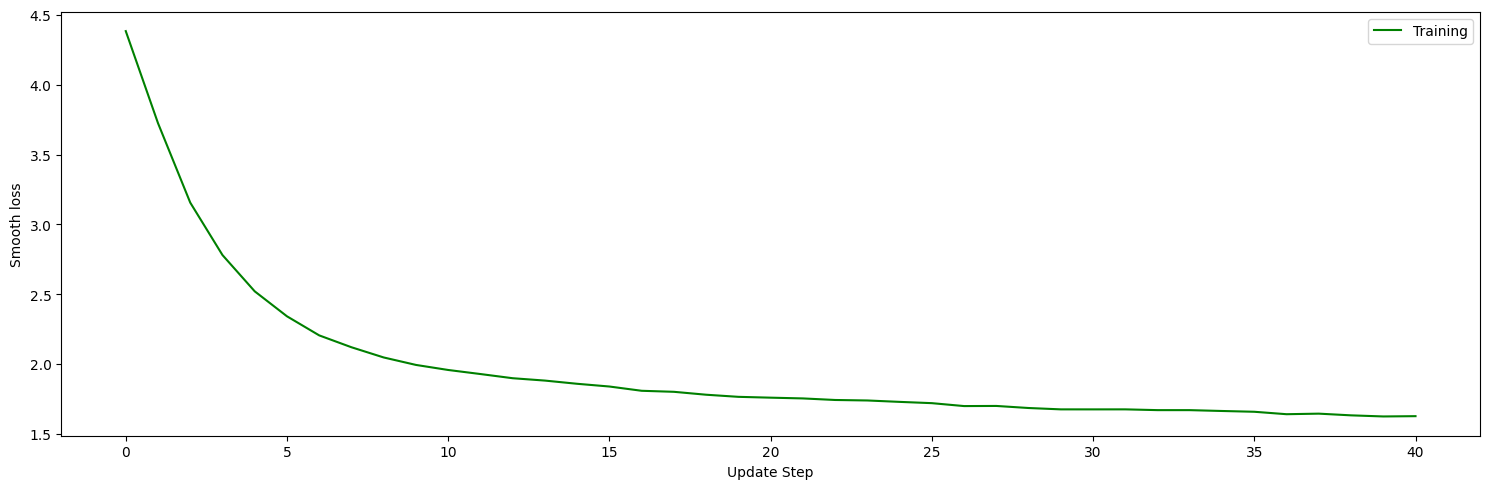

In [79]:
temperature_net = RecurrentNeuralNetwork(data_handler)
temperature_net.add_layer([
    RecurrentLayer(temperature_net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(temperature_net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_loss = temperature_net.train_random_order(25, 0.001, 4, 8, best_model_file_name="temperature_net.npz")

In [80]:
print(f"{"="*10} Temperature 0.01 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, T=0.01)))

print(f"{"="*10} Temperature 0.5 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, T=0.5)))

print(f"{"="*10} Temperature 0.99 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, T=0.99)))

========== Temperature 0.01 ==========
zkarreas of the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the s

In [81]:
print(f"{"="*10} Theta 0.01 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, theta=0.01)))

print(f"{"="*10} Theta 0.5 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, theta=0.5)))

print(f"{"="*10} Theta 0.99 {"="*10}")
print(''.join(temperature_net.synthesize(n=1000, theta=0.99)))

========== Theta 0.01 ==========
e to the part of the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the starting to the st